# Prédiction de la qualité de soudures sur aciers — Notebook d'exploration

**Cours de Machine Learning — 3A**
**Équipe n° :** _(à compléter)_ · **Membres / mails :** _(à compléter)_ · **Date :** _(à compléter)_

---

## Objet de ce notebook

Ce notebook correspond à la **première phase** du projet : *comprendre et maîtriser la base de données
avant de modéliser*. Il couvre :

1. La **traduction de la problématique métier en tâche de Machine Learning**.
2. Le **chargement et le parsing robuste** du fichier brut `welddb.data` (format non trivial).
3. L'**analyse descriptive** (types, distributions, valeurs manquantes).
4. Le **pré-processing** : chaque décision est explicitée, décrite et justifiée (unités, valeurs
   censurées, variables catégorielles, stratégie face aux manquants, normalisation).
5. Une **Analyse en Composantes Principales (ACP)** pour développer de l'intuition.
6. L'**explicitation et la justification de la stratégie ML** (supervisé + semi-supervisé), qui sera
   mise en œuvre dans un second notebook.


## 1. De la problématique métier à la tâche de Machine Learning

### 1.1 Problématique métier
La qualité des soudures sur aciers est un enjeu industriel majeur (pipelines, mâts d'éoliennes, etc.).
Aujourd'hui, cette connaissance se transmet surtout **d'expert à expert**. L'objectif est d'**acquérir
et d'homogénéiser cette connaissance via les données**, et éventuellement de **découvrir de nouveaux
patterns** reliant la fabrication de la soudure à sa qualité.

### 1.2 Le dataset n'a PAS de colonne « qualité » — c'est à nous de la définir
Le fichier contient **44 colonnes** que l'on peut regrouper en trois familles :

| Famille | Colonnes | Rôle dans la modélisation |
|---|---|---|
| **Composition chimique** | 1–21 (C, Si, Mn, Ni, Cr, …, O, N, B en ppm) | **Entrées (features)** — ce que l'on contrôle |
| **Paramètres du procédé** | 22–30 (courant, tension, AC/DC, apport de chaleur, type de soudure, traitement post-soudure…) | **Entrées (features)** — ce que l'on contrôle |
| **Propriétés mécaniques** | 31–38 (limite d'élasticité, résistance, allongement, **ténacité Charpy**, dureté, FATT) | **Sorties = mesures de la QUALITÉ** |
| **Microstructure** | 39–43 (% ferrite, martensite…) | Sorties intermédiaires (mécanisme physique) |

La **qualité de soudure** est donc un *concept* que l'on traduit par une (ou plusieurs) **propriété(s)
mécanique(s) cible(s)** à prédire **à partir de la composition et du procédé**.

### 1.3 Notre choix de cible : la ténacité Charpy (colonne 36)
Une bonne soudure doit être **résistante** *et* **tenace** (résister à la fissuration / rupture fragile).
La **ténacité Charpy** (énergie absorbée lors d'un choc, en Joules) est l'indicateur n°1 de **fiabilité**
d'une soudure en service : c'est la rupture fragile qui cause les défaillances catastrophiques.
Nous analyserons les 4 propriétés (Yield, UTS, Allongement, Charpy) mais la **pipeline ML principale
prédira la ténacité Charpy**.

### 1.4 Tâche de ML
- **Tâche principale :** *régression* — prédire la ténacité Charpy (J) à partir de la composition + procédé.
- **Pourquoi aussi du semi-supervisé :** la cible Charpy n'est renseignée que pour **~53 % des lignes**
  (le reste vaut `N` = non reporté). Les lignes **sans cible** gardent pourtant une composition/procédé
  exploitables → ce sont des **données non labellisées** que les méthodes semi-supervisées savent valoriser.


## 2. Imports et configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

## 3. Chargement et parsing du fichier brut

Le fichier `welddb.data` est un texte **séparé par des espaces, sans en-tête**, avec plusieurs pièges :

- **`N` = valeur non reportée** (et *non* une valeur nulle ! un zéro signifierait « élément absent »,
  `N` signifie « on ne sait pas »). → à convertir en `NaN`.
- **Valeurs censurées** de type `<0.0005`, `<5`, `<100` : ce sont des mesures *sous la limite de
  détection* de l'instrument (left-censored). → stratégie dédiée (voir §5).
- **Dureté** au format `143(Hv30)` : valeur numérique + échelle entre parenthèses. → extraction par regex.
- **Colonnes catégorielles** : AC/DC (24), polarité d'électrode (25), type de soudure (28), identifiant (44).

On commence par charger **tout en texte** pour maîtriser le nettoyage colonne par colonne.

In [2]:
# Noms de colonnes (courts, exploitables) + unités, d'après welddb.info
COLS = [
    ("C","wt%"),("Si","wt%"),("Mn","wt%"),("S","wt%"),("P","wt%"),("Ni","wt%"),
    ("Cr","wt%"),("Mo","wt%"),("V","wt%"),("Cu","wt%"),("Co","wt%"),("W","wt%"),
    ("O_ppm","ppm"),("Ti_ppm","ppm"),("N_ppm","ppm"),("Al_ppm","ppm"),("B_ppm","ppm"),
    ("Nb_ppm","ppm"),("Sn_ppm","ppm"),("As_ppm","ppm"),("Sb_ppm","ppm"),
    ("Current","A"),("Voltage","V"),("AC_DC","cat"),("Polarity","cat"),
    ("HeatInput","kJ/mm"),("InterpassTemp","degC"),("WeldType","cat"),
    ("PWHT_temp","degC"),("PWHT_time","h"),
    ("YieldStrength","MPa"),("UTS","MPa"),("Elongation","%"),("ReductionArea","%"),
    ("CharpyTemp","degC"),("CharpyToughness","J"),("Hardness","kg/mm2"),("FATT50","degC"),
    ("PrimaryFerrite","%"),("FerriteSecondPhase","%"),("AcicularFerrite","%"),
    ("Martensite","%"),("FerriteCarbide","%"),("WeldID","id"),
]
col_names = [c for c,_ in COLS]
UNITS = {c:u for c,u in COLS}

DATA_PATH = "data/welddb.data"
raw = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=col_names, dtype=str)
print("Dimensions brutes :", raw.shape)
raw.head(3)

Dimensions brutes : (1652, 44)


,C,Si,Mn,S,P,Ni,Cr,Mo,V,Cu,Co,W,O_ppm,Ti_ppm,N_ppm,Al_ppm,B_ppm,Nb_ppm,Sn_ppm,As_ppm,Sb_ppm,Current,Voltage,AC_DC,Polarity,HeatInput,InterpassTemp,WeldType,PWHT_temp,PWHT_time,YieldStrength,UTS,Elongation,ReductionArea,CharpyTemp,CharpyToughness,Hardness,FATT50,PrimaryFerrite,FerriteSecondPhase,AcicularFerrite,Martensite,FerriteCarbide,WeldID
0,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,250,14,392,466,31.9,80.6,N,N,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,0,0,N,N,N,N,-28,100,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.30,0.65,0.008,0.012,0,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,170,21,DC,+,1,200,MMA,580,2,370,456,35.2,80.6,-38,100,N,N,N,N,N,N,N,Evans-Ni/CMn-1990/1991-0Aht


In [3]:
# --- Fonctions de nettoyage -------------------------------------------------
def clean_numeric(series):
    # Convertit une colonne texte en numerique :
    #  - 'N'          -> NaN (non reporte)
    #  - '<x'         -> NaN ici (traite separement en §5 pour garder la trace de la censure)
    #  - '143(Hv30)'  -> 143.0 (on extrait le nombre de tete)
    def conv(v):
        if v is None: return np.nan
        v = str(v).strip()
        if v == "N" or v == "": return np.nan
        if v.startswith("<") or v.startswith(">"):   # censuré -> géré plus tard
            return np.nan
        m = re.match(r"^-?\d*\.?\d+", v)              # nombre de tête (gère '143(Hv30)')
        return float(m.group()) if m else np.nan
    return series.map(conv)

def censor_flag(series):
    # Renvoie (valeur_limite, est_censure) pour les tokens '<x'.
    lim, cens = [], []
    for v in series:
        v = str(v).strip()
        if v.startswith("<"):
            cens.append(True);  lim.append(float(v[1:]))
        else:
            cens.append(False); lim.append(np.nan)
    return pd.Series(lim, index=series.index), pd.Series(cens, index=series.index)

CAT_COLS = ["AC_DC","Polarity","WeldType"]
ID_COL   = "WeldID"
NUM_COLS = [c for c in col_names if c not in CAT_COLS + [ID_COL]]
print(f"{len(NUM_COLS)} colonnes numériques, {len(CAT_COLS)} catégorielles, 1 identifiant.")

40 colonnes numériques, 3 catégorielles, 1 identifiant.


In [4]:
# --- Construction du DataFrame propre --------------------------------------
df = pd.DataFrame(index=raw.index)

# 1) Mémoriser la censure (combien de valeurs '<x' par colonne) AVANT conversion
censor_counts = {}
for c in NUM_COLS:
    _, cens = censor_flag(raw[c])
    if cens.any():
        censor_counts[c] = int(cens.sum())

# 2) Colonnes numériques
for c in NUM_COLS:
    df[c] = clean_numeric(raw[c])

# 3) Colonnes catégorielles : 'N' -> NaN, polarité '0' -> 'none' (soudage AC, pas de polarité DC)
for c in CAT_COLS:
    s = raw[c].replace("N", np.nan)
    if c == "Polarity":
        s = s.replace("0", "none")
    df[c] = s.astype("category")

# 4) Identifiant conservé tel quel
df[ID_COL] = raw[ID_COL]

print("Valeurs censurées (<LOD) détectées par colonne :")
for k,v in sorted(censor_counts.items(), key=lambda x:-x[1]):
    print(f"  {k:>8} : {v}")
df.head(3)

Valeurs censurées (<LOD) détectées par colonne :
     B_ppm : 419
    Al_ppm : 403
         V : 308
    Nb_ppm : 299
    Ti_ppm : 70
        Co : 21
        Cu : 14
         W : 12
    As_ppm : 8
         S : 7
    Sb_ppm : 6
    Sn_ppm : 5
        Mo : 2
  PrimaryFerrite : 2


,C,Si,Mn,S,P,Ni,Cr,Mo,V,Cu,Co,W,O_ppm,Ti_ppm,N_ppm,Al_ppm,B_ppm,Nb_ppm,Sn_ppm,As_ppm,Sb_ppm,Current,Voltage,HeatInput,InterpassTemp,PWHT_temp,PWHT_time,YieldStrength,UTS,Elongation,ReductionArea,CharpyTemp,CharpyToughness,Hardness,FATT50,PrimaryFerrite,FerriteSecondPhase,AcicularFerrite,Martensite,FerriteCarbide,AC_DC,Polarity,WeldType,WeldID
0,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,1.0,200.0,250.0,14.0,392.0,466.0,31.9,80.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,1.0,200.0,0.0,0.0,NaN,NaN,NaN,NaN,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,1.0,200.0,580.0,2.0,370.0,456.0,35.2,80.6,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DC,+,MMA,Evans-Ni/CMn-1990/1991-0Aht


## 4. Analyse descriptive

### 4.1 Types et aperçu statistique

In [5]:
print("Dimensions :", df.shape)
print("\nTypes de colonnes :")
print(df.dtypes.value_counts())
df.describe().T[["count","mean","std","min","25%","50%","75%","max"]]

Dimensions : (1652, 44)

Types de colonnes :
float64     40
category     1
category     1
category     1
object       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
C,1652.0,0.075521,0.023898,0.029,0.06175,0.074,0.086,0.18
Si,1652.0,0.328577,0.112455,0.040,0.27000,0.320,0.360,1.14
Mn,1652.0,1.202821,0.382137,0.270,0.94000,1.270,1.440,2.25
S,1641.0,0.009561,0.011239,0.001,0.00600,0.007,0.010,0.14
P,1642.0,0.012952,0.019627,0.002,0.00700,0.010,0.014,0.25
Ni,697.0,0.415034,0.786951,0.000,0.00000,0.067,0.260,3.50
Cr,784.0,2.101273,3.026548,0.000,0.00000,0.530,2.300,10.20
Mo,791.0,0.480358,0.477423,0.000,0.00000,0.340,1.010,1.50
V,620.0,0.072443,0.096364,0.000,0.00400,0.015,0.180,0.32
Cu,564.0,0.176188,0.325897,0.000,0.00000,0.030,0.190,1.63


### 4.2 Variables catégorielles

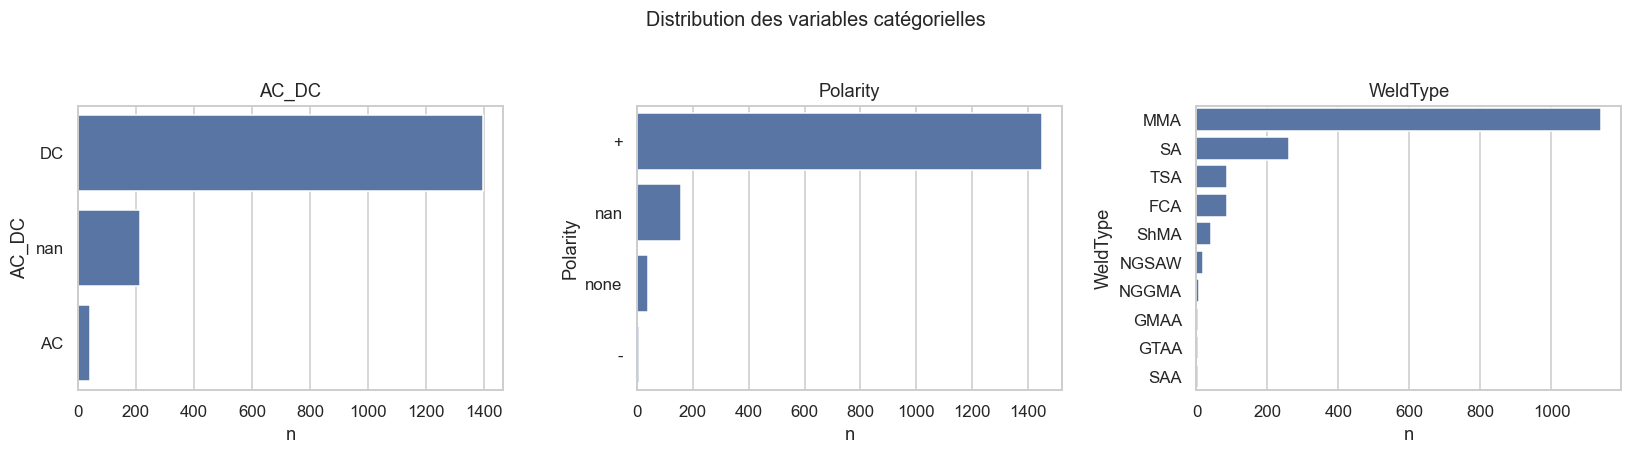

Type de soudure dominant : MMA (manual metal arc) ~69 % des lignes.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axes, CAT_COLS):
    vc = df[c].value_counts(dropna=False)
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="#4C72B0")
    ax.set_title(f"{c}"); ax.set_xlabel("n")
plt.suptitle("Distribution des variables catégorielles", y=1.03, fontsize=13)
plt.tight_layout(); plt.show()

print("Type de soudure dominant : MMA (manual metal arc) ~69 % des lignes.")

### 4.3 Valeurs manquantes 

La carte révèle que le dataset est très lacunaire et structuré par
blocs (campagnes expérimentales différentes qui ne mesuraient pas les mêmes grandeurs).

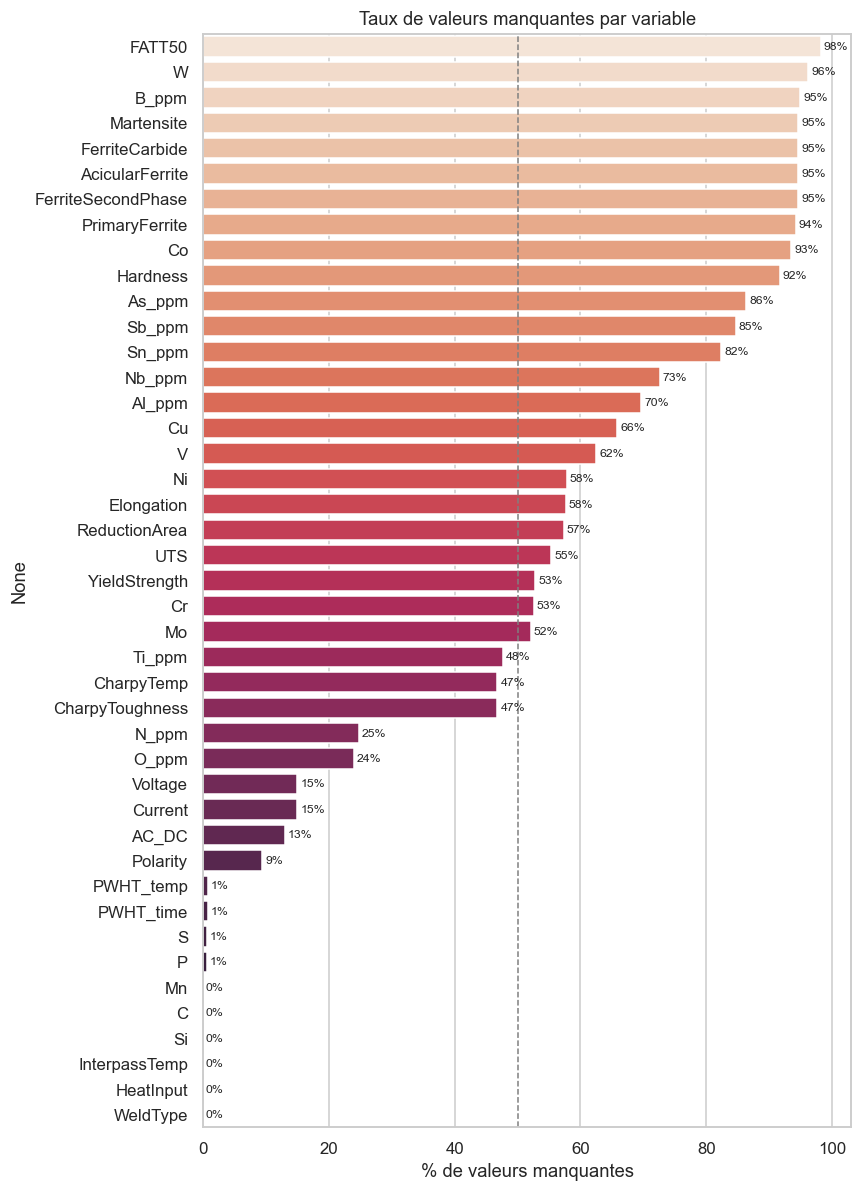

In [7]:
miss = df.drop(columns=[ID_COL]).isna().mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 11))
sns.barplot(x=miss.values, y=miss.index, ax=ax, palette="rocket_r")
ax.axvline(50, color="grey", ls="--", lw=1)
ax.set_xlabel("% de valeurs manquantes"); ax.set_title("Taux de valeurs manquantes par variable")
for i,(v) in enumerate(miss.values):
    ax.text(v+0.5, i, f"{v:.0f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

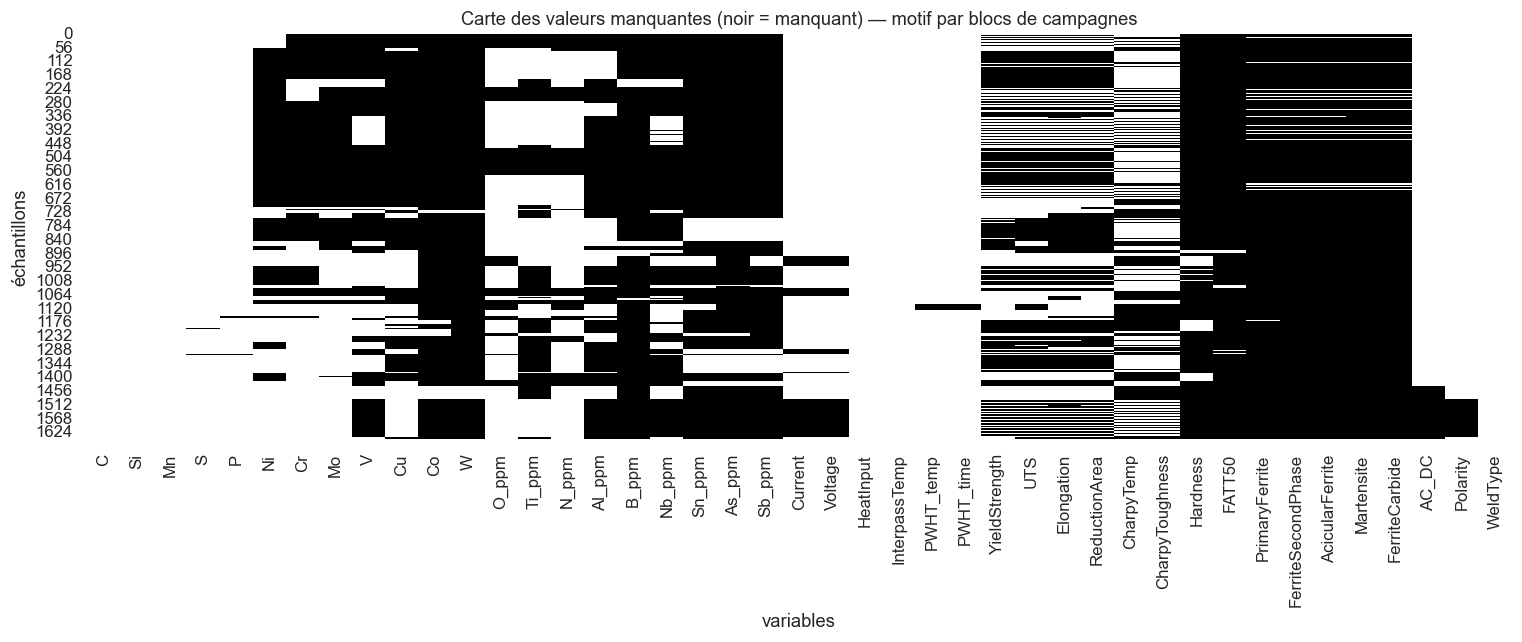

In [8]:
# Carte des manquants (motif par blocs)
plt.figure(figsize=(14,6))
sns.heatmap(df.drop(columns=[ID_COL]).isna(), cbar=False, cmap="Greys")
plt.title("Carte des valeurs manquantes (noir = manquant) — motif par blocs de campagnes")
plt.xlabel("variables"); plt.ylabel("échantillons")
plt.tight_layout(); plt.show()

**Lecture :**
- Certaines colonnes de composition sont renseignées quasi partout (C, Si, Mn) ; d'autres presque jamais
  (Co, W, Sn, As, Sb > 80 % de manquants).
- Les propriétés mécaniques (dont la **ténacité Charpy, ~47 % de manquants**) ne sont mesurées que sur
  une partie des échantillons.
- Le motif **par blocs** confirme que les données agrègent **plusieurs études** aux protocoles différents.

Ces constats dictent directement la stratégie de pré-processing (§5) et justifient le recours au
**semi-supervisé** (§7).

## 5. Pré-processing 

### 5.1 Unités et cohérence physique
Les concentrations sont en **% massique** (éléments majeurs) ou en **ppm** (éléments traces : O, Ti, N, Al,
B, Nb, Sn, As, Sb). On **garde les unités d'origine** mais on retient que les échelles sont très
hétérogènes (du ppm au millier de MPa) → la **normalisation sera indispensable** pour l'ACP et pour les
modèles sensibles aux échelles .

### 5.2 Valeurs manquantes `N`
`N` = *non reporté* ≠ 0. On les a converties en `NaN`. Deux leviers :
- **Supprimer** les colonnes trop lacunaires (peu d'information, risque de biais d'imputation).
- **Imputer** les colonnes modérément lacunaires au moment de la modélisation (dans un `Pipeline`, pour
  éviter toute fuite de données entre train et test).

### 5.3 Valeurs censurées `<LOD` (sous limite de détection)
Un token `<5` signifie « teneur inférieure à 5 ppm, non quantifiable ». Convention classique et défendable :
imputer par **LOD/2** (meilleur compromis sans biaiser systématiquement vers 0 ou vers la limite). On a
conservé le **compte de censures** par colonne pour en discuter.

In [9]:
# 5.2 — Suppression des colonnes de composition trop lacunaires (> 70 % manquants)
SEUIL_DROP = 0.70
taux = df.drop(columns=[ID_COL]).isna().mean()
to_drop = taux[(taux > SEUIL_DROP)].index.tolist()
# On ne supprime pas les cibles mécaniques même si lacunaires (ce sont nos labels)
TARGETS = ["YieldStrength","UTS","Elongation","ReductionArea",
           "CharpyToughness","Hardness"]
to_drop = [c for c in to_drop if c not in TARGETS]
print("Colonnes supprimées (>70% manquantes, hors cibles) :", to_drop)

df2 = df.drop(columns=to_drop).copy()
print("Dimensions après suppression :", df2.shape)

Colonnes supprimées (>70% manquantes, hors cibles) : ['Co', 'W', 'B_ppm', 'Nb_ppm', 'Sn_ppm', 'As_ppm', 'Sb_ppm', 'FATT50', 'PrimaryFerrite', 'FerriteSecondPhase', 'AcicularFerrite', 'Martensite', 'FerriteCarbide']
Dimensions après suppression : (1652, 31)


In [10]:
# 5.3 — Imputation des valeurs censurées <LOD par LOD/2, réinjectées dans df2
for c, n in censor_counts.items():
    if c in df2.columns:
        lim, cens = censor_flag(raw[c])
        mask = cens & df2[c].isna()          # lignes censurées encore NaN
        df2.loc[mask, c] = lim[mask] / 2.0
print("Valeurs censurées imputées par LOD/2.")

# Microstructure : un NaN peut ici signifier 'phase absente' selon les études -> on NE l'impute pas
# automatiquement, on le laissera de côté pour la modélisation (variable intermédiaire, pas une entrée).
MICRO = ["PrimaryFerrite","FerriteSecondPhase","AcicularFerrite","Martensite","FerriteCarbide"]
MICRO = [m for m in MICRO if m in df2.columns]
print("Colonnes microstructure disponibles :", MICRO)

Valeurs censurées imputées par LOD/2.
Colonnes microstructure disponibles : []


### 5.4 Définition explicite des rôles : features vs cibles
On fige ici la **séparation entrées / sorties**, cohérente avec le §1.

In [11]:
FEATURES_NUM = [c for c in df2.columns
                if c not in TARGETS + MICRO + CAT_COLS + [ID_COL]]
FEATURES_CAT = [c for c in CAT_COLS if c in df2.columns]

print("FEATURES numériques (composition + procédé) :")
print(" ", FEATURES_NUM)
print("\nFEATURES catégorielles :", FEATURES_CAT)
print("\nCIBLES mécaniques (mesures de qualité) :", [t for t in TARGETS if t in df2.columns])
print("\nCible PRINCIPALE : CharpyToughness (J)")

FEATURES numériques (composition + procédé) :
  ['C', 'Si', 'Mn', 'S', 'P', 'Ni', 'Cr', 'Mo', 'V', 'Cu', 'O_ppm', 'Ti_ppm', 'N_ppm', 'Al_ppm', 'Current', 'Voltage', 'HeatInput', 'InterpassTemp', 'PWHT_temp', 'PWHT_time', 'CharpyTemp']

FEATURES catégorielles : ['AC_DC', 'Polarity', 'WeldType']

CIBLES mécaniques (mesures de qualité) : ['YieldStrength', 'UTS', 'Elongation', 'ReductionArea', 'CharpyToughness', 'Hardness']

Cible PRINCIPALE : CharpyToughness (J)


### 5.5 Faut-il normaliser ?
**Oui, pour l'ACP et les modèles à base de distances / gradients.** Les variables vont du ppm (ex. Bore)
au millier de MPa : sans standardisation, l'ACP serait dominée par les variables à grande variance
purement à cause de leur unité. On applique un **`StandardScaler`** (centrage-réduction) pour l'ACP.
**Règle d'or : le scaler sera toujours ajusté sur le train
uniquement**, via un `Pipeline`, pour éviter toute fuite de données.

## 6. Comprendre les variables cibles de qualité

### 6.1 Disponibilité des labels par propriété mécanique

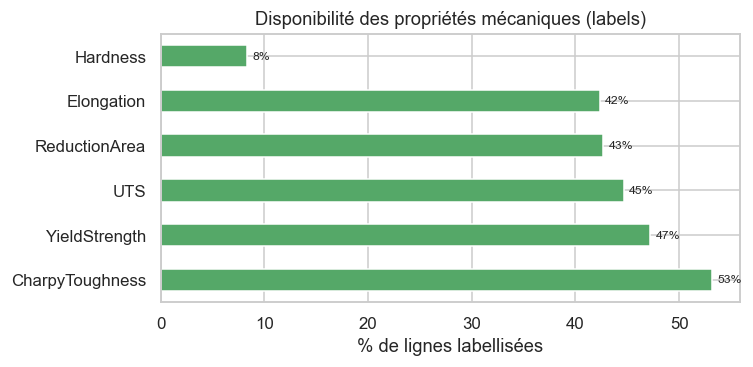

La ténacité Charpy est labellisée sur ~53% des lignes -> ~879 exemples supervisés.


In [12]:
dispo = (1 - df2[[t for t in TARGETS if t in df2.columns]].isna().mean())*100
dispo = dispo.sort_values(ascending=False)
ax = dispo.plot(kind="barh", color="#55A868", figsize=(7,3.5))
ax.set_xlabel("% de lignes labellisées"); ax.set_title("Disponibilité des propriétés mécaniques (labels)")
for i,v in enumerate(dispo.values): ax.text(v+0.5,i,f"{v:.0f}%",va="center",fontsize=8)
plt.tight_layout(); plt.show()
print("La ténacité Charpy est labellisée sur ~%.0f%% des lignes -> ~%d exemples supervisés."
      % (dispo['CharpyToughness'], df2['CharpyToughness'].notna().sum()))

### 6.2 Distribution de la cible principale (Charpy) et des autres propriétés

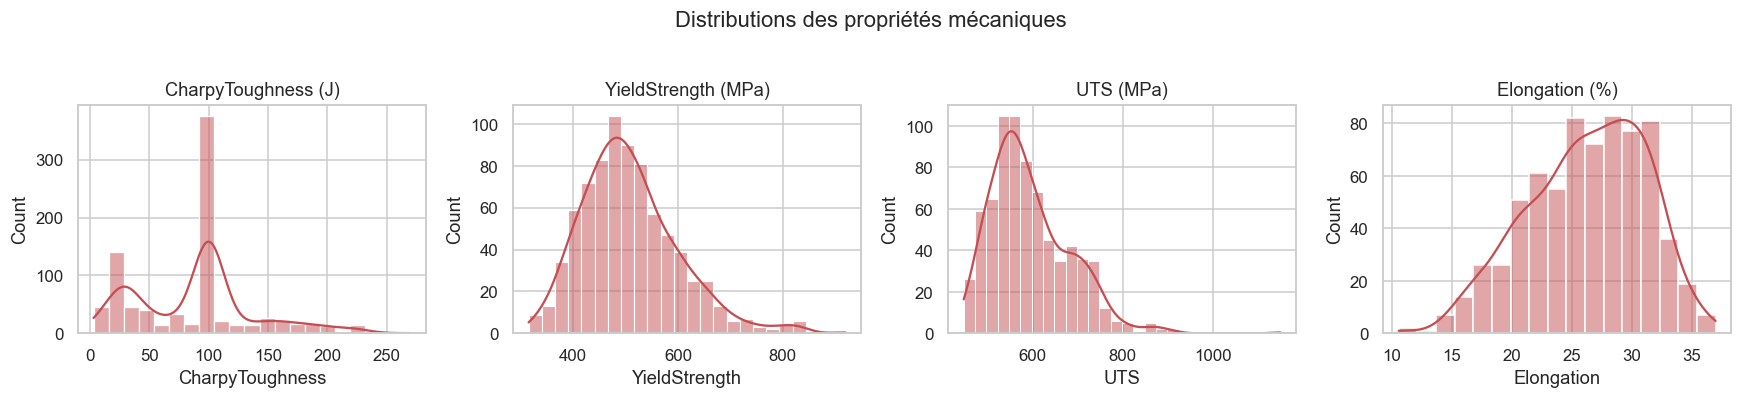

In [13]:
props = [t for t in ["CharpyToughness","YieldStrength","UTS","Elongation"] if t in df2.columns]
fig, axes = plt.subplots(1, len(props), figsize=(4*len(props),3.5))
for ax,p in zip(axes, props):
    sns.histplot(df2[p].dropna(), kde=True, ax=ax, color="#C44E52")
    ax.set_title(f"{p} ({UNITS.get(p,'')})")
plt.suptitle("Distributions des propriétés mécaniques", y=1.03); plt.tight_layout(); plt.show()

### 6.3 La ténacité Charpy dépend de la température d'essai
La ténacité Charpy n'a de sens **qu'à une température d'essai donnée** (`CharpyTemp`). C'est un point
physique crucial : la même soudure est tenace à chaud et fragile à froid. **`CharpyTemp` doit donc être
une feature du modèle** quand on prédit `CharpyToughness`.

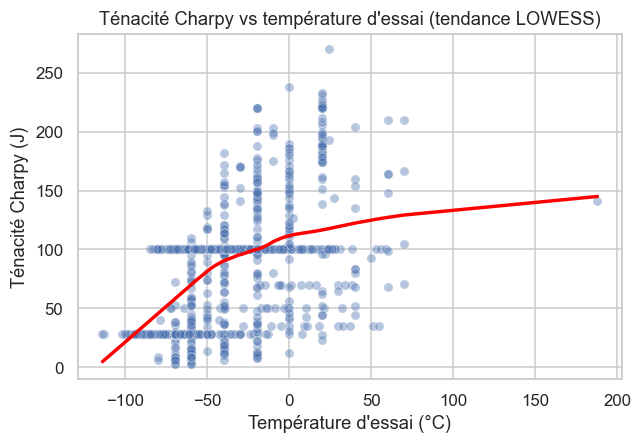

Corrélation Charpy~Temp : 0.47


In [14]:
sub = df2[["CharpyTemp","CharpyToughness"]].dropna()
plt.figure(figsize=(6,4.2))
sns.scatterplot(data=sub, x="CharpyTemp", y="CharpyToughness", alpha=0.4, color="#4C72B0")
sns.regplot(data=sub, x="CharpyTemp", y="CharpyToughness", scatter=False, lowess=True, color="red")
plt.title("Ténacité Charpy vs température d'essai (tendance LOWESS)")
plt.xlabel("Température d'essai (°C)"); plt.ylabel("Ténacité Charpy (J)")
plt.tight_layout(); plt.show()
print("Corrélation Charpy~Temp : %.2f" % sub.corr().iloc[0,1])

### 6.4 Corrélations features ↔ ténacité Charpy
On identifie les leviers (composition/procédé) les plus liés à la ténacité.

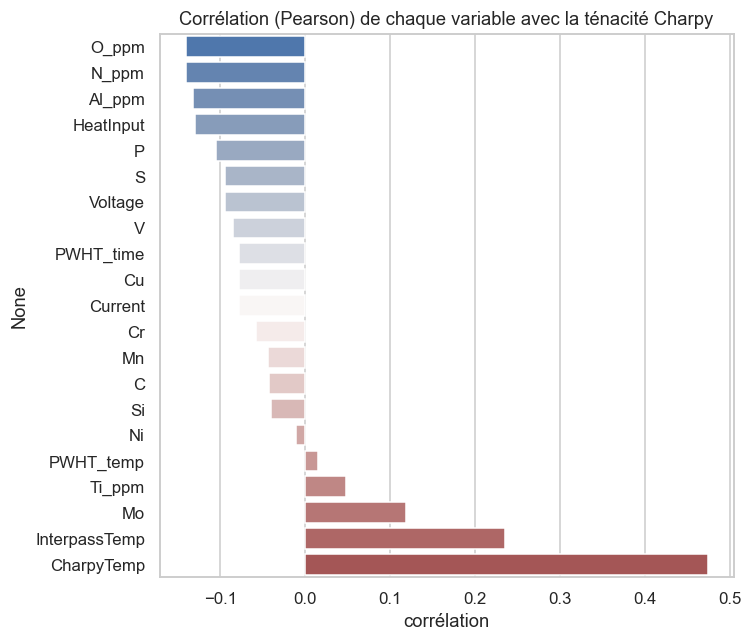

In [15]:
cols_corr = FEATURES_NUM + ["CharpyTemp","CharpyToughness"]
corr = df2[cols_corr].corr(numeric_only=True)
ch = corr["CharpyToughness"].drop("CharpyToughness").sort_values()
plt.figure(figsize=(7,6))
sns.barplot(x=ch.values, y=ch.index, palette="vlag")
plt.title("Corrélation (Pearson) de chaque variable avec la ténacité Charpy")
plt.xlabel("corrélation"); plt.tight_layout(); plt.show()

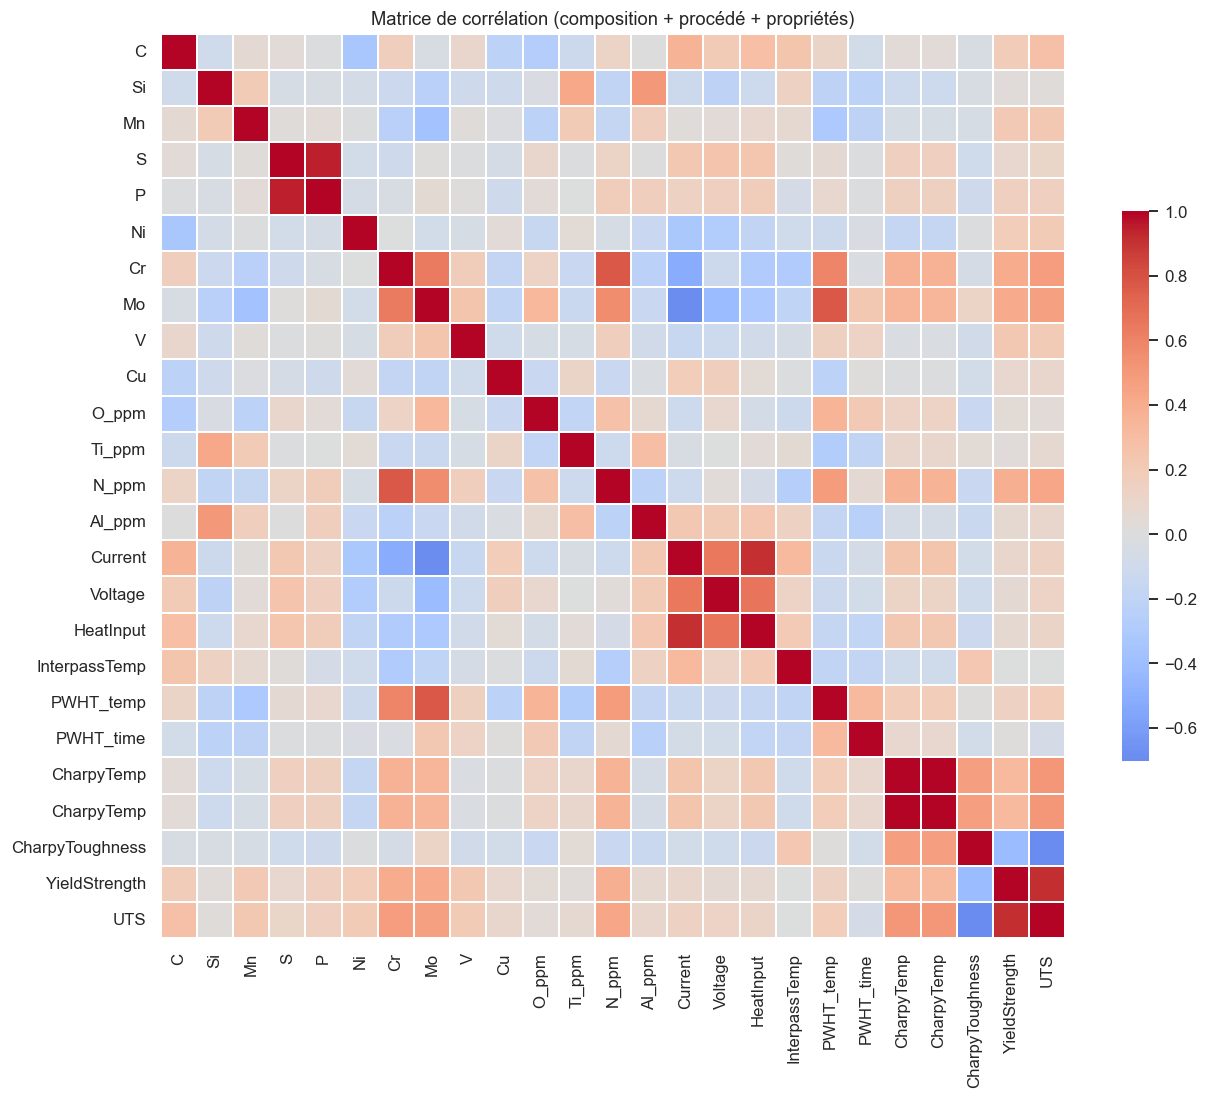

In [16]:
# Matrice de corrélation globale (features + cibles principales)
plt.figure(figsize=(12,10))
cm = df2[FEATURES_NUM + ["CharpyTemp","CharpyToughness","YieldStrength","UTS"]].corr()
sns.heatmap(cm, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink":.6}, linewidths=.3)
plt.title("Matrice de corrélation (composition + procédé + propriétés)")
plt.tight_layout(); plt.show()

## 7. Analyse en Composantes Principales (ACP)

Objectif : **développer de l'intuition**. L'ACP projette les échantillons dans un espace de dimension
réduite qui maximise la variance expliquée. On l'applique aux **features numériques standardisées**.
Pour pouvoir calculer l'ACP malgré les manquants, on **impute** (médiane) uniquement pour cette
visualisation — l'imputation « propre » (dans un Pipeline) sera faite à la modélisation.

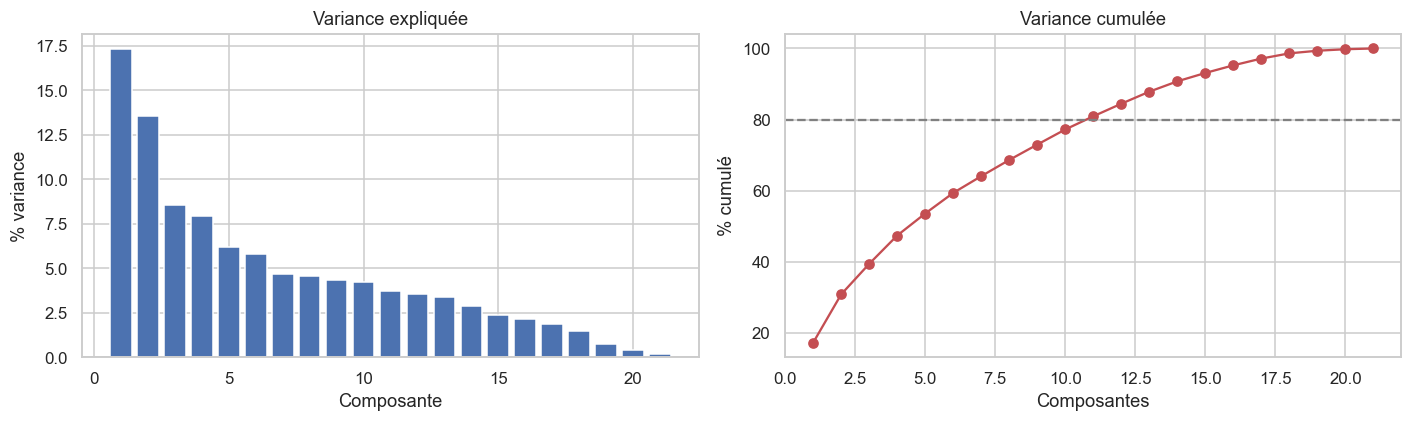

Variance expliquée PC1+PC2 : 30.9% | 80% de variance atteints à 11 composantes (sur 21).


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

X = df2[FEATURES_NUM].copy()
Xi = SimpleImputer(strategy="mean").fit_transform(X)
Xs = StandardScaler().fit_transform(Xi)

pca = PCA(n_components=Xs.shape[1], random_state=RANDOM_STATE)  # toutes les composantes
scores = pca.fit_transform(Xs)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80 = int(np.argmax(cum >= 0.8)) + 1 if (cum >= 0.8).any() else Xs.shape[1]

fig, (a1,a2) = plt.subplots(1,2, figsize=(13,4))
a1.bar(range(1,len(evr)+1), evr*100, color="#4C72B0")
a1.set_xlabel("Composante"); a1.set_ylabel("% variance"); a1.set_title("Variance expliquée")
a2.plot(range(1,len(evr)+1), np.cumsum(evr)*100, "o-", color="#C44E52")
a2.axhline(80, ls="--", color="grey"); a2.set_xlabel("Composantes"); a2.set_ylabel("% cumulé")
a2.set_title("Variance cumulée")
plt.tight_layout(); plt.show()
print("Variance expliquée PC1+PC2 : %.1f%% | 80%% de variance atteints à %d composantes (sur %d)."
      % (evr[:2].sum()*100, n80, Xs.shape[1]))

### 7.1 Cercle des corrélations (contributions des variables)

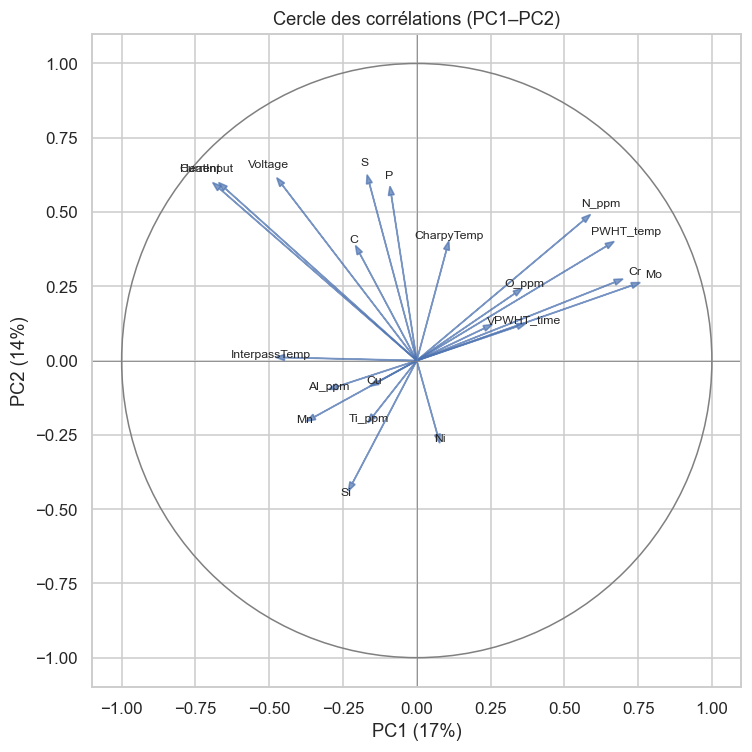

In [18]:
load = pca.components_.T * np.sqrt(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(7,7))
circle = plt.Circle((0,0),1, color="grey", fill=False)
ax.add_artist(circle)
for i, name in enumerate(FEATURES_NUM):
    ax.arrow(0,0, load[i,0], load[i,1], head_width=0.02, color="#4C72B0", alpha=0.7)
    ax.text(load[i,0]*1.1, load[i,1]*1.1, name, fontsize=8, ha="center")
ax.axhline(0,color="grey",lw=.5); ax.axvline(0,color="grey",lw=.5)
ax.set_xlim(-1.1,1.1); ax.set_ylim(-1.1,1.1)
ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}%)")
ax.set_title("Cercle des corrélations (PC1–PC2)")
plt.tight_layout(); plt.show()

### 7.2 Projection des échantillons, colorés par ténacité Charpy
On regarde si les soudures tenaces / fragiles se **séparent** dans le plan principal : un début de
structure justifierait qu'un modèle puisse apprendre la cible depuis composition + procédé.

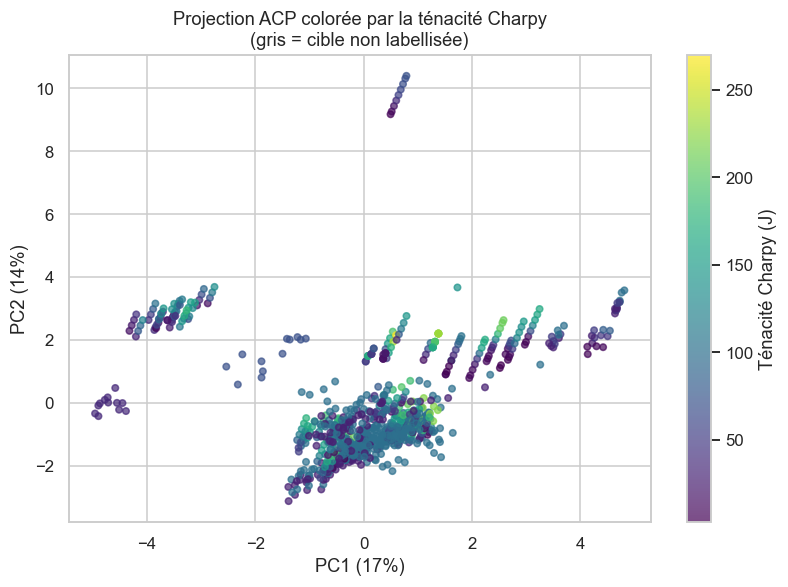

In [19]:
charpy = df2["CharpyToughness"].values
fig, ax = plt.subplots(figsize=(7.5,5.5))
sc = ax.scatter(scores[:,0], scores[:,1], c=charpy, cmap="viridis", s=18, alpha=0.7)
plt.colorbar(sc, label="Ténacité Charpy (J)")
ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}%)")
ax.set_title("Projection ACP colorée par la ténacité Charpy\n(gris = cible non labellisée)")
plt.tight_layout(); plt.show()

### 7.3 Projection colorée par type de soudure
L'ACP révèle-t-elle la structure « par campagnes / procédés » soupçonnée dans la carte des manquants ?

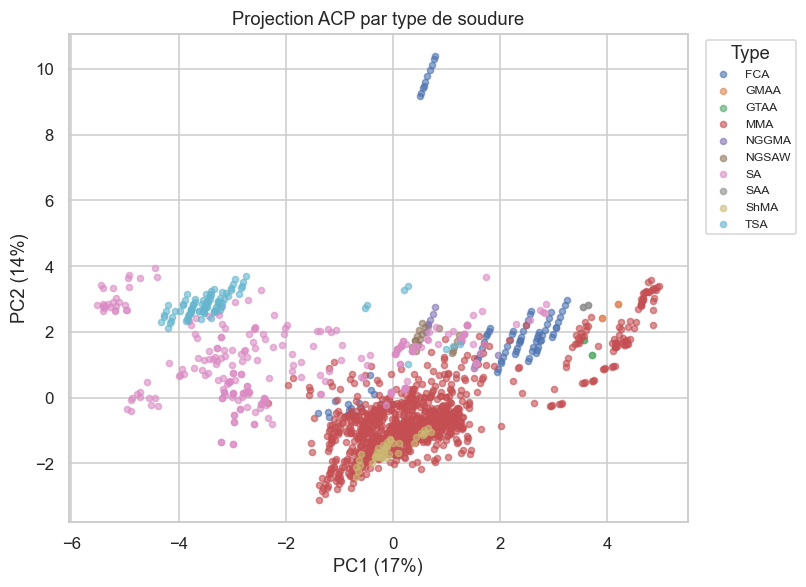

In [20]:
fig, ax = plt.subplots(figsize=(7.5,5.5))
for wt, g in pd.DataFrame({"PC1":scores[:,0],"PC2":scores[:,1],"WeldType":df2["WeldType"].values}).groupby("WeldType"):
    ax.scatter(g["PC1"], g["PC2"], s=16, alpha=0.6, label=wt)
ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}%)")
ax.legend(title="Type", bbox_to_anchor=(1.02,1), loc="upper left", fontsize=8)
ax.set_title("Projection ACP par type de soudure")
plt.tight_layout(); plt.show()

**Intuitions tirées de l'ACP :**
- Les premières composantes concentrent une part substantielle de la variance → une **structure de plus
  faible dimension** existe (beaucoup de variables sont corrélées, ex. éléments d'alliage entre eux).
- Le cercle des corrélations regroupe les variables physiquement liées (éléments d'alliage renforçant la
  trempabilité d'un côté, etc.) → cohérence métallurgique rassurante.
- Une structuration par **type de soudure / procédé** apparaît : il faudra en tenir compte (risque de
  confusion entre « effet procédé » et « effet composition »).

## 8. Stratégie de Machine Learning (explicitée et justifiée)

### 8.1 Formulation
- **Entrées (X)** : composition chimique retenue + paramètres procédé (+ `CharpyTemp`, indispensable pour
  la ténacité) + variables catégorielles encodées (`AC_DC`, `Polarity`, `WeldType`).
- **Sortie (y)** : `CharpyToughness` (J) — **régression**.
- Les ~47 % de lignes sans label Charpy forment le **réservoir non labellisé** pour le semi-supervisé.

### 8.2 Modèles supervisés envisagés (notebook 2)
| Modèle | Pourquoi |
|---|---|
| **Régression linéaire / Ridge / Lasso** | baseline interprétable ; Lasso = sélection de variables |
| **k-NN** | référence non paramétrique sensible aux échelles (teste l'intérêt du scaling) |
| **Random Forest / Gradient Boosting** | non-linéarités + interactions, robustes aux manquants/échelles, importance des variables |
| **SVR** | non-linéaire (noyau RBF), efficace en dimension modérée |

### 8.3 Protocole de validation croisée rigoureux
- **`Pipeline`** scikit-learn = imputation + scaling + modèle, **ajusté sur le train uniquement** →
  aucune fuite de données.
- **K-fold (k=5 ou 10)** répétée, + **`GridSearchCV`/`RandomizedSearchCV`** pour les hyperparamètres
  (validation croisée imbriquée pour une estimation non biaisée).
- **Attention à la structure par groupes** : plusieurs lignes proviennent d'une même étude/soudure
  (`WeldID`). Pour éviter un optimisme de fuite, on envisagera un **`GroupKFold`** sur l'identifiant.

### 8.4 Métriques (régression)
- **RMSE** et **MAE** (en Joules, interprétables métier), **R²** (part de variance expliquée).
- On comparera toujours à une **baseline naïve** (prédire la moyenne) pour valider le gain réel.

### 8.5 Volet semi-supervisé — justification et piste bibliographique
**Pourquoi ?** Près de la moitié des lignes n'ont pas de label Charpy mais portent une information
composition/procédé exploitable. Les méthodes semi-supervisées (SSL) tirent parti de ces données non
labellisées pour **régulariser** le modèle et améliorer la généralisation quand les labels sont rares/coûteux.

**Pistes à appliquer (au moins une, à justifier) :**
- **Self-training (pseudo-labelling)** : entraîner un régresseur sur les données labellisées, prédire les
  non labellisées, ré-injecter les prédictions les plus **confiantes** et ré-entraîner. Simple, applicable
  à tout régresseur (ex. `SelfTrainingRegressor` maison ou via `sklearn.semi_supervised` pour la variante
  classification si l'on bascule sur un score qualité).
- **Co-training / Label spreading** (hypothèse de variété/cluster : des points proches dans l'espace des
  features ont des cibles proches — cohérent avec la structure ACP observée).
- **Réduction de dimension semi-supervisée / pré-entraînement** (ex. features ACP ou auto-encodeur ajusté
  sur *toutes* les lignes, puis régression sur les labellisées).

> Référence fondatrice à citer dans le rapport : *Chapelle, Schölkopf & Zien, « Semi-Supervised Learning »,
> MIT Press, 2006*. Le choix précis sera arrêté et testé dans le notebook de modélisation.

## 9. Sauvegarde du dataset nettoyé et synthèse

In [21]:
import os
os.makedirs("data", exist_ok=True)
OUT = "data/welddb_clean.csv"
df2.to_csv(OUT, index=False)
print("Dataset nettoyé sauvegardé :", OUT, "| dimensions :", df2.shape)
print("\nColonnes conservées :")
print(list(df2.columns))

Dataset nettoyé sauvegardé : data/welddb_clean.csv | dimensions : (1652, 31)

Colonnes conservées :
['C', 'Si', 'Mn', 'S', 'P', 'Ni', 'Cr', 'Mo', 'V', 'Cu', 'O_ppm', 'Ti_ppm', 'N_ppm', 'Al_ppm', 'Current', 'Voltage', 'HeatInput', 'InterpassTemp', 'PWHT_temp', 'PWHT_time', 'YieldStrength', 'UTS', 'Elongation', 'ReductionArea', 'CharpyTemp', 'CharpyToughness', 'Hardness', 'AC_DC', 'Polarity', 'WeldType', 'WeldID']


## 10. Synthèse de l'exploration (à reprendre dans le rapport)

**Ce que l'on a établi :**
1. **La qualité n'est pas une colonne** : on l'a traduite par la **ténacité Charpy** (indicateur n°1 de
   fiabilité), avec les autres propriétés mécaniques en appui.
2. **Tâche ML = régression** de la ténacité Charpy à partir de composition + procédé, avec
   `CharpyTemp` comme feature obligatoire (dépendance physique forte).
3. **Données très lacunaires et structurées par blocs** (plusieurs campagnes) : suppression des colonnes
   > 80 % manquantes, imputation des censures `<LOD` par LOD/2, imputation du reste **dans le Pipeline**.
4. **Normalisation nécessaire** (échelles du ppm au millier de MPa) pour l'ACP et les modèles à distance.
5. **L'ACP** montre une structure de plus faible dimension et une organisation par type de procédé →
   un modèle a de quoi apprendre, mais il faudra gérer l'effet « procédé » et les groupes (`WeldID`).
6. **Environ la moitié des lignes ne sont pas labellisées** → justification directe d'une approche
   **semi-supervisée** (self-training en priorité).

**Prochaines étapes (notebook 2 — modélisation) :**
- Construire les `Pipeline` (impute + scale + modèle) et la **validation croisée** (GroupKFold sur `WeldID`).
- Entraîner et comparer les modèles supervisés (RMSE / MAE / R² vs baseline).
- Implémenter **≥ 1 méthode semi-supervisée** et mesurer son apport.
- Conclure sur l'approche la plus adaptée et formuler des **recommandations métier** (quels leviers de
  composition/procédé pour maximiser la ténacité).
